# Lab - EDA Bivariate Analysis: Amazon UK Product Insights

This notebook answers the questions from the README in a simple, beginner-friendly way.

We will look at:

- product categories and best-seller status
- product prices across categories
- product ratings across categories
- the relationship between price and rating

In [1]:
import os
from pathlib import Path

# This avoids a plotting warning on some computers.
os.environ.setdefault("MPLCONFIGDIR", "/tmp/mplconfig")
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_rows", 20)
pd.set_option("display.float_format", "{:,.4f}".format)

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7000,15308,21.9900,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7000,98099,23.9900,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7000,15308,21.9900,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7000,7205,31.9900,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6000,1881,17.9900,False,0,Hi-Fi Speakers


In [2]:
df.shape

(2443651, 9)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


## Part 1: Best-Seller Trends Across Product Categories

**Question:** Are some categories more likely to contain best-sellers?

In [4]:
# A crosstab counts how many products fall into each combination.
category_best_seller = pd.crosstab(df["category"], df["isBestSeller"])

category_best_seller.head()

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [5]:
# Rename the columns to make the table easier to read.
category_best_seller = category_best_seller.rename(
    columns={False: "not_best_seller", True: "best_seller"}
)

# Add totals and best-seller percentage.
category_best_seller["total_products"] = (
    category_best_seller["not_best_seller"] + category_best_seller["best_seller"]
)

category_best_seller["best_seller_percentage"] = (
    category_best_seller["best_seller"] / category_best_seller["total_products"] * 100
)

category_best_seller = category_best_seller.sort_values(
    "best_seller_percentage",
    ascending=False
)

category_best_seller.head(10)

isBestSeller,not_best_seller,best_seller,total_products,best_seller_percentage
category,,,,
Grocery,9008,556,9564,5.8135
Smart Home Security & Lighting,98,6,104,5.7692
Health & Personal Care,9017,552,9569,5.7686
Mobile Phone Accessories,248,11,259,4.2471
Power & Hand Tools,8353,306,8659,3.5339
"Billiard, Snooker & Pool",241,8,249,3.2129
Pet Supplies,9152,285,9437,3.0200
Home Brewing & Wine Making,239,7,246,2.8455
Wind Instruments,243,7,250,2.8000


In [6]:
# Very small categories can look artificially high.
# This version keeps only categories with at least 1,000 products.
category_best_seller_1000 = category_best_seller[
    category_best_seller["total_products"] >= 1000
]

category_best_seller_1000.head(10)

isBestSeller,not_best_seller,best_seller,total_products,best_seller_percentage
category,,,,
Grocery,9008,556,9564,5.8135
Health & Personal Care,9017,552,9569,5.7686
Power & Hand Tools,8353,306,8659,3.5339
Pet Supplies,9152,285,9437,3.0200
PC & Video Games,6008,157,6165,2.5466
Arts & Crafts,9319,230,9549,2.4086
Baby,14709,341,15050,2.2658
Large Appliances,7740,144,7884,1.8265
Hardware,8424,146,8570,1.7036


### Chi-Square Test

The chi-square test checks whether two categorical variables are related.

Here the variables are:

- `category`
- `isBestSeller`

If the chi-square statistic is very large, it means the real table is very different from what we would expect if the two variables were independent.

In [7]:
# We use the original crosstab for the chi-square test.
observed = pd.crosstab(df["category"], df["isBestSeller"])

row_totals = observed.sum(axis=1)
column_totals = observed.sum(axis=0)
grand_total = observed.values.sum()

# Expected values if category and best-seller status were independent.
expected = np.outer(row_totals, column_totals) / grand_total

# Chi-square formula: sum((observed - expected)^2 / expected)
chi_square = ((observed.values - expected) ** 2 / expected).sum()

degrees_of_freedom = (observed.shape[0] - 1) * (observed.shape[1] - 1)

chi_square, degrees_of_freedom

(np.float64(36540.20270061387), 295)

In [8]:
# Cramer's V tells us how strong the relationship is.
# 0 means no relationship. Closer to 1 means a stronger relationship.
number_of_rows, number_of_columns = observed.shape

cramers_v = np.sqrt(
    chi_square / (grand_total * min(number_of_rows - 1, number_of_columns - 1))
)

cramers_v

np.float64(0.1222829439760564)

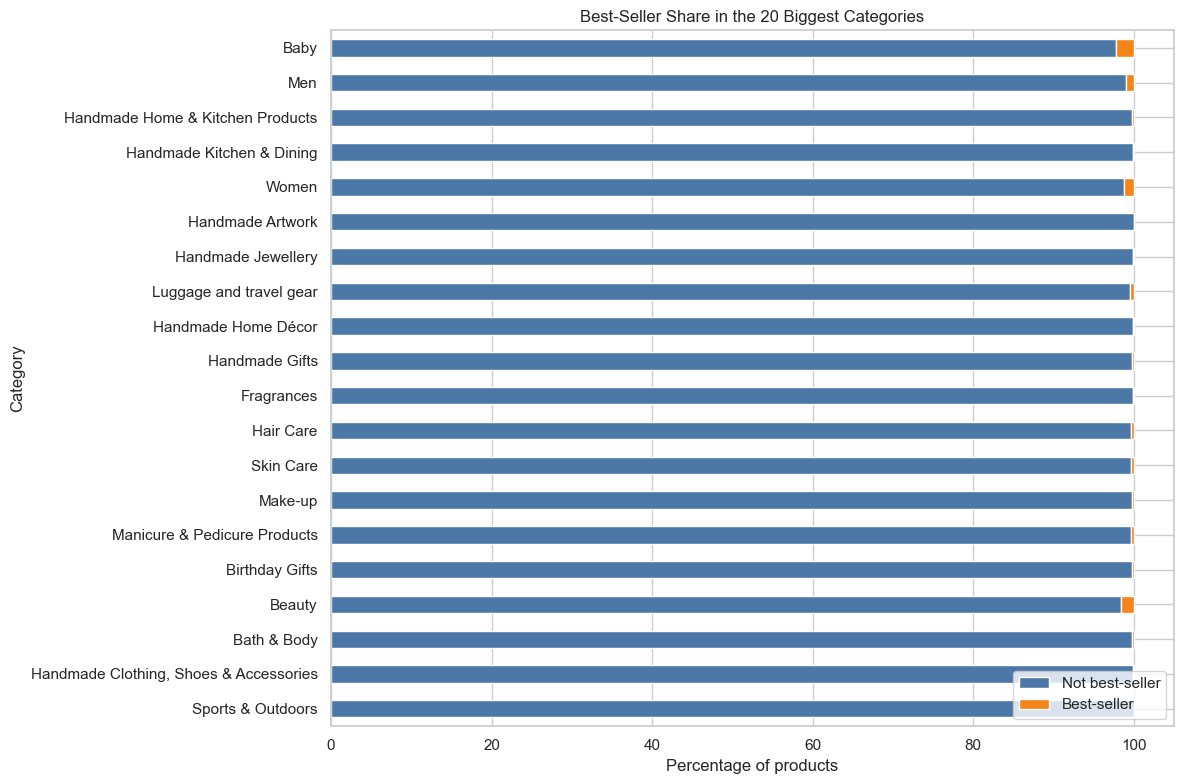

In [9]:
# Stacked bar chart for the 20 biggest categories.
top_20_categories = (
    pd.crosstab(df["category"], df["isBestSeller"])
    .sort_values(False, ascending=False)
    .head(20)
)

top_20_percent = top_20_categories.div(top_20_categories.sum(axis=1), axis=0) * 100
top_20_percent = top_20_percent.rename(columns={False: "Not best-seller", True: "Best-seller"})

top_20_percent.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 8),
    color=["#4C78A8", "#F58518"]
)

plt.title("Best-Seller Share in the 20 Biggest Categories")
plt.xlabel("Percentage of products")
plt.ylabel("Category")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [10]:
best_category = category_best_seller_1000.iloc[0]

display(Markdown(f'''
### Part 1 Answer

The category with the highest best-seller percentage, after keeping only categories with at least 1,000 products, is **{best_category.name}**.

It has **{best_category["best_seller_percentage"]:.2f}%** best-sellers.

The chi-square statistic is **{chi_square:,.2f}**, which is very large compared with the degrees of freedom (**{degrees_of_freedom}**). This tells us that `category` and `isBestSeller` are not independent.

However, Cramer's V is only **{cramers_v:.3f}**. That means the relationship exists, but it is weak.

**Business meaning:** category affects best-seller chances, but it does not fully explain why a product becomes a best-seller.
'''))


### Part 1 Answer

The category with the highest best-seller percentage, after keeping only categories with at least 1,000 products, is **Grocery**.

It has **5.81%** best-sellers.

The chi-square statistic is **36,540.20**, which is very large compared with the degrees of freedom (**295**). This tells us that `category` and `isBestSeller` are not independent.

However, Cramer's V is only **0.122**. That means the relationship exists, but it is weak.

**Business meaning:** category affects best-seller chances, but it does not fully explain why a product becomes a best-seller.


## Part 2: Product Prices and Ratings Across Categories

Before comparing prices, we remove price outliers using the IQR method.

IQR means:

`Q3 - Q1`

We remove prices above:

`Q3 + 1.5 * IQR`

In [11]:
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
iqr = q3 - q1

lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

q1, q3, iqr, lower_limit, upper_limit

(np.float64(9.99),
 np.float64(45.99),
 np.float64(36.0),
 np.float64(-44.01),
 np.float64(99.99000000000001))

In [12]:
df_clean = df[
    (df["price"] >= lower_limit) &
    (df["price"] <= upper_limit)
]

rows_removed = len(df) - len(df_clean)
percent_removed = rows_removed / len(df) * 100

len(df), len(df_clean), rows_removed, percent_removed

(2443651, 2115963, 327688, 13.409770871536075)

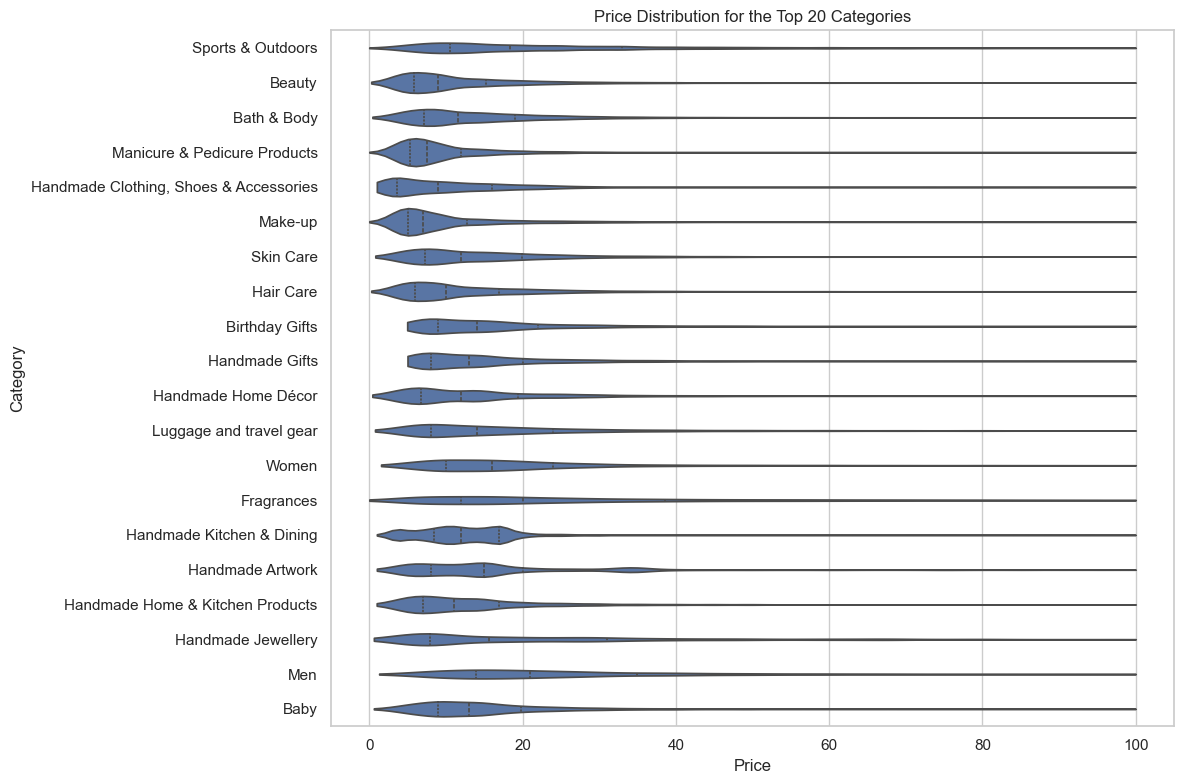

In [13]:
top_20_category_names = df_clean["category"].value_counts().head(20).index
top_20_data = df_clean[df_clean["category"].isin(top_20_category_names)]

plt.figure(figsize=(12, 8))
sns.violinplot(
    data=top_20_data,
    x="price",
    y="category",
    order=top_20_category_names,
    inner="quartile",
    cut=0
)

plt.title("Price Distribution for the Top 20 Categories")
plt.xlabel("Price")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [14]:
median_price_by_category = (
    df_clean
    .groupby("category")["price"]
    .median()
    .sort_values(ascending=False)
)

median_price_by_category.head(10)

category
Desktop PCs              74.0000
Boxing Shoes             69.7900
Tablets                  69.0000
Graphics Cards           68.5400
Motherboards             67.9200
Made in Italy Handmade   64.0000
Digital Frames           63.9000
Streaming Clients        62.6800
Golf Shoes               62.3900
Ski Helmets              61.3300
Name: price, dtype: float64

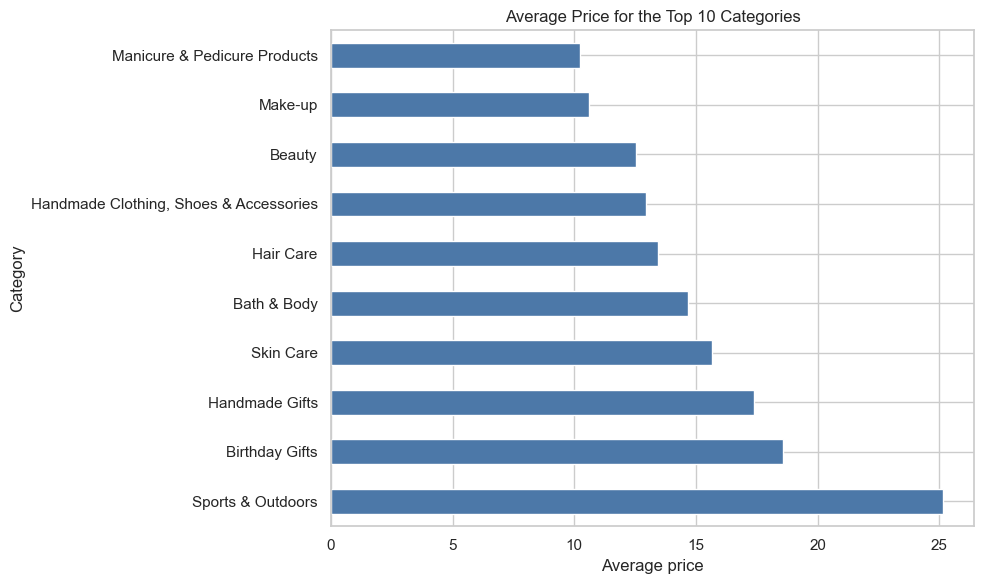

In [15]:
top_10_category_names = df_clean["category"].value_counts().head(10).index

average_price_top_10 = (
    df_clean[df_clean["category"].isin(top_10_category_names)]
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

average_price_top_10.plot(kind="barh", figsize=(10, 6), color="#4C78A8")

plt.title("Average Price for the Top 10 Categories")
plt.xlabel("Average price")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [16]:
average_price_by_category = (
    df_clean
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

average_price_by_category.head(10)

category
Motherboards        68.7724
Boxing Shoes        67.4178
Desktop PCs         66.9156
Tablets             66.5530
Graphics Cards      65.1035
Digital Frames      60.7451
Streaming Clients   60.2418
Hockey Shoes        60.0948
Computer Cases      58.3399
Skiing Poles        57.8678
Name: price, dtype: float64

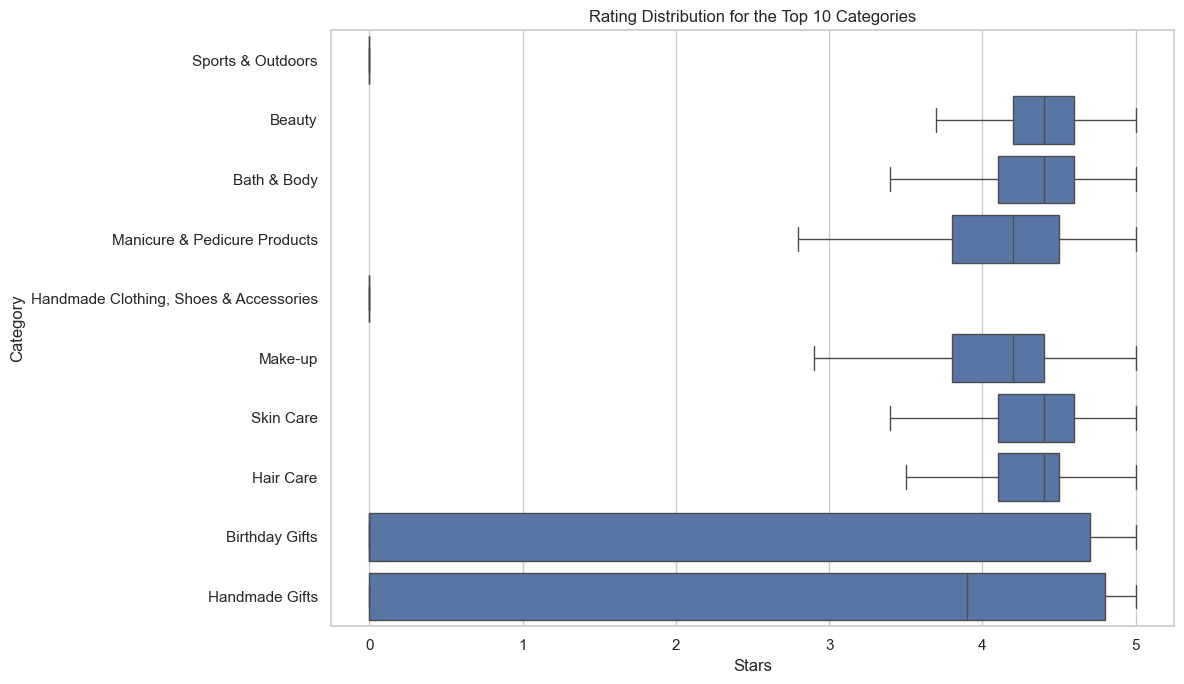

In [17]:
top_10_data = df_clean[df_clean["category"].isin(top_10_category_names)]

plt.figure(figsize=(12, 7))
sns.boxplot(
    data=top_10_data,
    x="stars",
    y="category",
    order=top_10_category_names,
    showfliers=False
)

plt.title("Rating Distribution for the Top 10 Categories")
plt.xlabel("Stars")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [18]:
median_rating_by_category = (
    df_clean
    .groupby("category")["stars"]
    .median()
    .sort_values(ascending=False)
)

median_rating_by_category.head(10)

category
Computer Memory                4.7000
Building & Construction Toys   4.6000
Office Paper Products          4.6000
Luxury Food & Drink            4.6000
Kids' Play Figures             4.6000
Hobbies                        4.6000
Beer, Wine & Spirits           4.6000
Laptop Accessories             4.6000
Cables & Accessories           4.5000
CPUs                           4.5000
Name: stars, dtype: float64

In [19]:
# Many products have stars = 0.
# This usually means "no rating yet", not a real 0-star review.
# So we also check ratings only for products above 0.
df_rated = df_clean[df_clean["stars"] > 0]

median_rating_rated_only = (
    df_rated
    .groupby("category")["stars"]
    .median()
    .sort_values(ascending=False)
)

median_rating_rated_only.head(10)

category
Made in Italy Handmade                   5.0000
Handmade Baby Products                   5.0000
Handmade Artwork                         5.0000
Handmade Kitchen & Dining                4.9000
Handmade Clothing, Shoes & Accessories   4.9000
Handmade Gifts                           4.8000
Birthday Gifts                           4.8000
Handmade Home Décor                      4.8000
Handmade Home & Kitchen Products         4.7000
Gifts for Him                            4.7000
Name: stars, dtype: float64

In [20]:
highest_median_price_category = median_price_by_category.index[0]
highest_median_price = median_price_by_category.iloc[0]

highest_average_price_category = average_price_by_category.index[0]
highest_average_price = average_price_by_category.iloc[0]

highest_median_rating_category = median_rating_by_category.index[0]
highest_median_rating = median_rating_by_category.iloc[0]

highest_rated_only_category = median_rating_rated_only.index[0]
highest_rated_only_rating = median_rating_rated_only.iloc[0]

display(Markdown(f'''
### Part 2 Answer

The IQR method removed **{rows_removed:,.0f}** products, which is **{percent_removed:.2f}%** of the dataset.

After removing price outliers:

- The category with the highest median price is **{highest_median_price_category}**, with a median price of **GBP {highest_median_price:,.2f}**.
- The category with the highest average price is **{highest_average_price_category}**, with an average price of **GBP {highest_average_price:,.2f}**.
- The category with the highest raw median rating is **{highest_median_rating_category}**, with a median rating of **{highest_median_rating:.1f}**.
- If we ignore products with `stars = 0`, the highest median rating category is **{highest_rated_only_category}**, with a median rating of **{highest_rated_only_rating:.1f}**.

**Business meaning:** product category clearly affects price. Some categories are naturally more expensive, even after removing extreme prices. Ratings are harder to interpret because many products have no rating yet.
'''))


### Part 2 Answer

The IQR method removed **327,688** products, which is **13.41%** of the dataset.

After removing price outliers:

- The category with the highest median price is **Desktop PCs**, with a median price of **GBP 74.00**.
- The category with the highest average price is **Motherboards**, with an average price of **GBP 68.77**.
- The category with the highest raw median rating is **Computer Memory**, with a median rating of **4.7**.
- If we ignore products with `stars = 0`, the highest median rating category is **Made in Italy Handmade**, with a median rating of **5.0**.

**Business meaning:** product category clearly affects price. Some categories are naturally more expensive, even after removing extreme prices. Ratings are harder to interpret because many products have no rating yet.


## Part 3: Relationship Between Price and Rating

**Question:** Do expensive products usually have better ratings?

In [21]:
price_rating_correlation = df_clean["price"].corr(df_clean["stars"])
price_rating_correlation

np.float64(-0.07767299878181001)

In [22]:
price_rating_correlation_rated_only = df_rated["price"].corr(df_rated["stars"])
price_rating_correlation_rated_only

np.float64(0.006744508067158054)

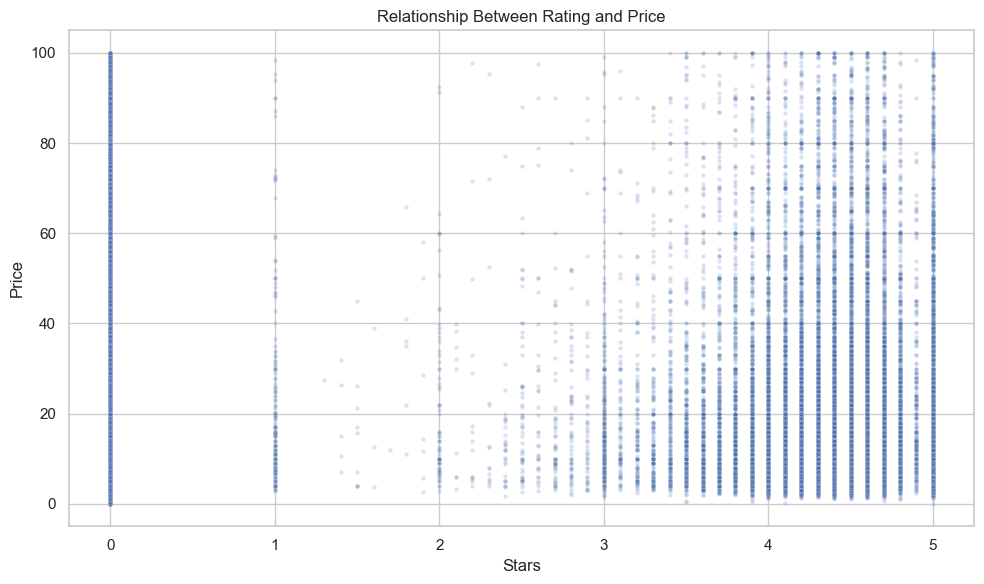

In [23]:
# A scatter plot with all rows would be too crowded,
# so we take a random sample.
sample_data = df_clean.sample(50000, random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=sample_data,
    x="stars",
    y="price",
    alpha=0.2,
    s=10
)

plt.title("Relationship Between Rating and Price")
plt.xlabel("Stars")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

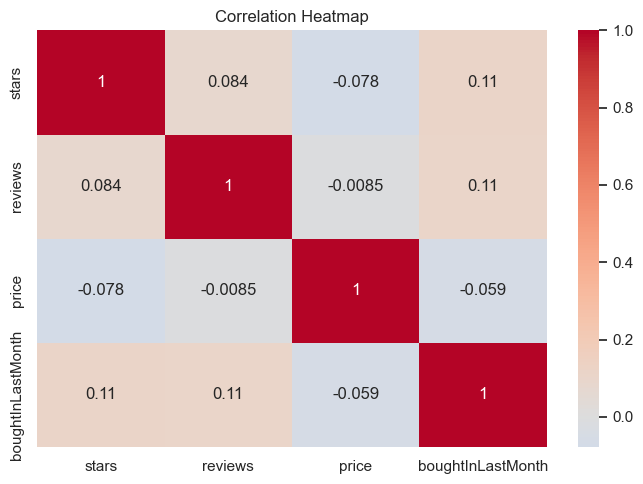

,stars,reviews,price,boughtInLastMonth
stars,1.0000,0.0839,-0.0777,0.1140
reviews,0.0839,1.0000,-0.0085,0.1056
price,-0.0777,-0.0085,1.0000,-0.0591
boughtInLastMonth,0.1140,0.1056,-0.0591,1.0000


In [24]:
numeric_columns = ["stars", "reviews", "price", "boughtInLastMonth"]
correlation_matrix = df_clean[numeric_columns].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

correlation_matrix

### QQ Plot

A QQ plot helps us check whether prices look normally distributed.

To keep this simple, we compare our sorted prices with sorted values from a normal distribution that has the same mean and standard deviation.

If prices were normal, the points would roughly follow the red line.

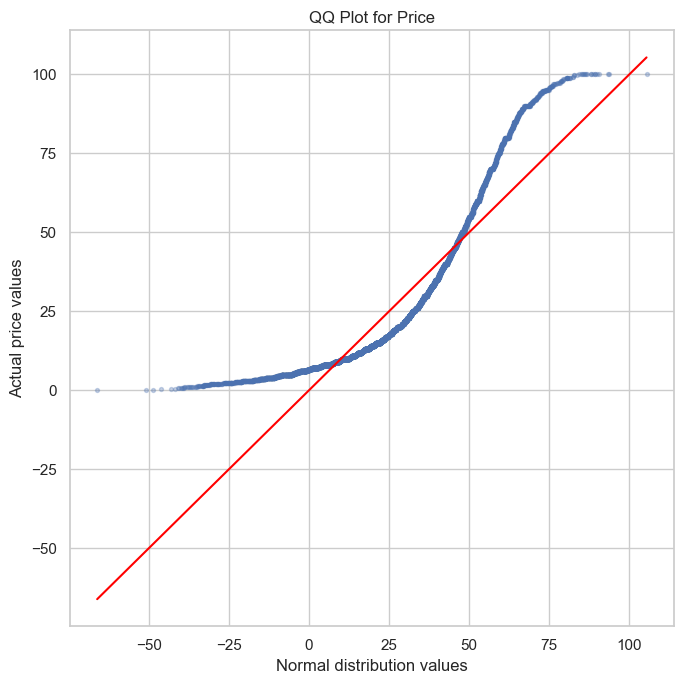

In [25]:
price_sample = df_clean["price"].sample(10000, random_state=42)

normal_sample = np.random.default_rng(42).normal(
    loc=price_sample.mean(),
    scale=price_sample.std(),
    size=len(price_sample)
)

sorted_prices = np.sort(price_sample)
sorted_normal = np.sort(normal_sample)

plt.figure(figsize=(7, 7))
plt.scatter(sorted_normal, sorted_prices, alpha=0.3, s=8)

line_min = min(sorted_normal.min(), sorted_prices.min())
line_max = max(sorted_normal.max(), sorted_prices.max())
plt.plot([line_min, line_max], [line_min, line_max], color="red")

plt.title("QQ Plot for Price")
plt.xlabel("Normal distribution values")
plt.ylabel("Actual price values")
plt.tight_layout()
plt.show()

In [26]:
display(Markdown(f'''
### Part 3 Answer

The correlation between `price` and `stars` is **{price_rating_correlation:.3f}** after removing price outliers.

This is very close to 0, so there is **no strong relationship** between price and rating.

If we only use products with more than 0 stars, the correlation is **{price_rating_correlation_rated_only:.3f}**, which is also very close to 0.

The scatter plot confirms this: higher-priced products do not clearly receive higher ratings.

The QQ plot shows that prices do not follow a normal distribution, because the points do not stay close to the red line.

**Business meaning:** a higher price does not guarantee a higher rating. Customers seem to rate products based on more than price alone.
'''))


### Part 3 Answer

The correlation between `price` and `stars` is **-0.078** after removing price outliers.

This is very close to 0, so there is **no strong relationship** between price and rating.

If we only use products with more than 0 stars, the correlation is **0.007**, which is also very close to 0.

The scatter plot confirms this: higher-priced products do not clearly receive higher ratings.

The QQ plot shows that prices do not follow a normal distribution, because the points do not stay close to the red line.

**Business meaning:** a higher price does not guarantee a higher rating. Customers seem to rate products based on more than price alone.


## Bonus: What Happens If We Do Not Remove Price Outliers?

In [27]:
original_average_price = df["price"].mean()
clean_average_price = df_clean["price"].mean()

original_median_price = df["price"].median()
clean_median_price = df_clean["price"].median()

original_correlation = df["price"].corr(df["stars"])
clean_correlation = df_clean["price"].corr(df_clean["stars"])

comparison = pd.DataFrame({
    "dataset": ["Original data", "After removing price outliers"],
    "average_price": [original_average_price, clean_average_price],
    "median_price": [original_median_price, clean_median_price],
    "price_rating_correlation": [original_correlation, clean_correlation],
    "maximum_price": [df["price"].max(), df_clean["price"].max()]
})

comparison

,dataset,average_price,median_price,price_rating_correlation,maximum_price
0,Original data,89.2438,19.0900,-0.1249,"100,000.0000"
1,After removing price outliers,23.4083,15.9900,-0.0777,99.9900


In [28]:
display(Markdown(f'''
### Bonus Answer

Without removing outliers, the average price is much higher because a few very expensive products pull it upward.

The original maximum price is **GBP {df["price"].max():,.2f}**, while the maximum after outlier removal is **GBP {df_clean["price"].max():,.2f}**.

This shows why outliers matter: they can make prices look higher than they are for most products.

**Business meaning:** when studying typical product prices, it is better to remove or separately analyze extreme prices.
'''))


### Bonus Answer

Without removing outliers, the average price is much higher because a few very expensive products pull it upward.

The original maximum price is **GBP 100,000.00**, while the maximum after outlier removal is **GBP 99.99**.

This shows why outliers matter: they can make prices look higher than they are for most products.

**Business meaning:** when studying typical product prices, it is better to remove or separately analyze extreme prices.


## Final Business Summary

In [29]:
display(Markdown(f'''
- Some categories have a higher best-seller percentage than others.
- The chi-square result shows category and best-seller status are related.
- Cramer's V is **{cramers_v:.3f}**, so the relationship is weak.
- Category has a clear effect on price.
- Price and rating have almost no linear relationship.
- Price outliers strongly affect averages, so removing them makes the analysis easier to understand.
'''))


- Some categories have a higher best-seller percentage than others.
- The chi-square result shows category and best-seller status are related.
- Cramer's V is **0.122**, so the relationship is weak.
- Category has a clear effect on price.
- Price and rating have almost no linear relationship.
- Price outliers strongly affect averages, so removing them makes the analysis easier to understand.
